# F26-11 — Phase 4: Evaluation and Analysis of Results
**Lightweight Speech Emotion Recognition Using Hand-Crafted Acoustic Features**

AI2002 Artificial Intelligence (BS-SE-5A), FAST-NUCES Lahore, Fall 2026 · Track B (Research & Development)
Members: 22L-7786 (Lead), 23L-3002, 23L-3102 · Instructor: Hajra Waheed

This notebook evaluates the models built in Phase 3 (SVM, Random Forest, 1D-CNN, CNN-BiLSTM and their
ensemble) under five test protocols, compares them, analyses where they fail and checks for gender bias.

It reads the saved per-clip predictions in `results/predictions_*.csv`. They were written by
`scripts/run_experiments.py`, which trains the same models as the Phase 3 notebook under every protocol
(23 deep-model training runs). Evaluating saved predictions takes seconds and needs no TensorFlow.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest, mannwhitneyu, norm
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
RESULTS = ROOT / "results"
OUT = ROOT / "phase4"
(OUT / "figures").mkdir(parents=True, exist_ok=True)

EMOTIONS = ["neutral", "happy", "sad", "angry", "fearful", "disgust", "surprised"]
MODELS = ["Majority", "SVM", "RandomForest", "CNN", "CNN_BiLSTM", "Ensemble"]
PROTOCOLS = {"paper": "Random split (paper)", "leaky": "Augment before split",
             "speaker": "Unseen speakers", "ravdess_to_tess": "RAVDESS → TESS",
             "tess_to_ravdess": "TESS → RAVDESS"}
COLORS = {"SVM": "#2a78d6", "RandomForest": "#eb6834", "CNN": "#1baf7a", "CNN_BiLSTM": "#eda100",
          "Ensemble": "#e87ba4"}
rng = np.random.default_rng(42)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
                     "font.size": 9})

## 1. Load the saved predictions
One row per test clip, model and protocol: true label, predicted label, speaker and gender.

| Protocol | Train | Test | Question |
|---|---|---|---|
| Random split (paper) | 80% of RAVDESS clips (+ augmented copies) | 144 RAVDESS clips | Does the model work? |
| Augment before split | 80% of all 5,760 augmented samples | 576 samples | Does the paper's split order inflate accuracy? |
| Unseen speakers | 18 actors, 4 folds | 6 new actors per fold (all 1,440 clips) | Does it work for new voices? |
| RAVDESS → TESS | all of RAVDESS | 2,800 TESS clips | Does it work on a new dataset? |
| TESS → RAVDESS | all of TESS | 1,440 RAVDESS clips | The reverse direction |

In [2]:
def load_predictions():
    """All saved per-clip predictions in one table, with a column saying if each prediction is right."""
    files = sorted(RESULTS.glob("predictions_*.csv"))
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    df["correct"] = df["pred"] == df["label"]
    return df


preds = load_predictions()
main = preds[preds["variant"] == "full"]
print(main.groupby(["experiment", "model"]).size().unstack()[MODELS])

model            Majority   SVM  RandomForest   CNN  CNN_BiLSTM  Ensemble
experiment                                                               
leaky                 576   576           576   576         576       576
paper                 144   144           144   144         144       144
ravdess_to_tess      2800  2800          2800  2800        2800      2800
speaker              1440  1440          1440  1440        1440      1440
tess_to_ravdess      1440  1440          1440  1440        1440      1440


## 2. Evaluation metrics
* **Accuracy**: share of correct predictions.
* **Macro-F1**: F1 of every emotion, averaged, so each emotion counts equally (RAVDESS has more neutral clips).
* **Weighted F1**: the metric the base paper reports, used only to compare with it.
* **95% confidence interval** of accuracy: we resample the test clips 2,000 times (bootstrap). A wide interval
  means the test set is too small to trust small differences.

In [3]:
def scores(df):
    """Accuracy, macro-F1, weighted-F1, macro precision and macro recall of one set of predictions."""
    y, p = df["label"], df["pred"]
    kw = dict(labels=range(len(EMOTIONS)), zero_division=0)
    return {"n": len(df), "accuracy": accuracy_score(y, p),
            "macro_F1": f1_score(y, p, average="macro", **kw),
            "weighted_F1": f1_score(y, p, average="weighted", **kw),
            "precision": precision_score(y, p, average="macro", **kw),
            "recall": recall_score(y, p, average="macro", **kw)}


def bootstrap_ci(correct, n_boot=2000):
    """95% confidence interval of accuracy, by resampling the test clips with replacement."""
    correct = np.asarray(correct, dtype=float)
    samples = rng.choice(correct, size=(n_boot, len(correct)))
    return np.percentile(samples.mean(axis=1), [2.5, 97.5])


rows = []
for exp, name in PROTOCOLS.items():
    for model in MODELS:
        d = main[(main["experiment"] == exp) & (main["model"] == model)]
        low, high = bootstrap_ci(d["correct"])
        rows.append({"experiment": exp, "protocol": name, "model": model, **scores(d),
                     "ci_low": low, "ci_high": high})
metrics = pd.DataFrame(rows)
metrics.to_csv(OUT / "metrics.csv", index=False)
print((metrics.set_index(["protocol", "model"]).drop(columns=["experiment", "n"]) * 100).round(1))

                                   accuracy  macro_F1  weighted_F1  precision  \
protocol             model                                                      
Random split (paper) Majority          20.1       4.8          6.8        2.9   
                     SVM               77.1      76.7         76.9       77.9   
                     RandomForest      69.4      68.0         68.4       72.0   
                     CNN               79.2      78.6         79.0       80.1   
                     CNN_BiLSTM        81.2      80.6         81.1       82.3   
                     Ensemble          81.9      81.4         81.9       82.4   
Augment before split Majority          20.0       4.8          6.6        2.9   
                     SVM               85.6      85.4         85.6       85.4   
                     RandomForest      71.5      70.5         70.7       75.6   
                     CNN               95.7      95.7         95.6       96.0   
                     CNN_BiL

In [4]:
summary = json.load(open(RESULTS / "summary.json"))
for r in summary["model_comparison"]:
    mine = metrics[(metrics["experiment"] == r["experiment"]) & (metrics["model"] == r["model"])].iloc[0]
    assert abs(mine["accuracy"] - r["acc"]) < 1e-9 and abs(mine["macro_F1"] - r["f1_macro"]) < 1e-9
print("All accuracies and macro-F1 values match results/summary.json.")

speaker = main[main["experiment"] == "speaker"]
folds = speaker.groupby(["model", "fold"])["correct"].mean().unstack()
print("\nUnseen speakers, accuracy per fold (%):")
print((folds.loc[MODELS] * 100).round(1).assign(mean=lambda t: t.mean(axis=1).round(1),
                                                std=lambda t: t.iloc[:, :4].std(axis=1, ddof=0).round(1)))

All accuracies and macro-F1 values match results/summary.json.

Unseen speakers, accuracy per fold (%):
fold             0     1     2     3  mean  std
model                                          
Majority      20.0  20.0  20.0  20.0  20.0  0.0
SVM           54.2  50.8  42.5  48.9  49.1  4.3
RandomForest  51.1  45.3  44.2  46.7  46.8  2.6
CNN           56.7  59.7  54.2  56.1  56.7  2.0
CNN_BiLSTM    60.3  56.1  52.2  57.5  56.5  2.9
Ensemble      59.2  60.8  55.6  58.3  58.5  1.9


## 3. Comparison of models
**McNemar's test** compares two models on the *same* test clips. It only looks at clips where exactly one of
the two models is right; if both models were equally good, those clips would split 50/50. A small p-value
(< 0.05) means the difference is real and not luck.

In [5]:
def mcnemar(df, model_a, model_b):
    """Clips only model A gets right, clips only model B gets right, and the exact McNemar p-value."""
    a = df[df["model"] == model_a]
    b = df[df["model"] == model_b]
    assert (a["path"].values == b["path"].values).all()
    a, b = a["correct"].values, b["correct"].values
    only_a, only_b = int(np.sum(a & ~b)), int(np.sum(~a & b))
    p = binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return only_a, only_b, p


pairs = [("Ensemble", "SVM"), ("Ensemble", "CNN"), ("CNN_BiLSTM", "CNN"), ("SVM", "RandomForest")]
rows = []
for exp, name in PROTOCOLS.items():
    d = main[main["experiment"] == exp]
    for a, b in pairs:
        only_a, only_b, p = mcnemar(d, a, b)
        rows.append({"protocol": name, "comparison": f"{a} vs {b}", "only A right": only_a,
                     "only B right": only_b, "p_value": round(p, 4)})
mcnemar_table = pd.DataFrame(rows)
mcnemar_table.to_csv(OUT / "mcnemar.csv", index=False)
print(mcnemar_table.to_string(index=False))

            protocol          comparison  only A right  only B right  p_value
Random split (paper)     Ensemble vs SVM            20            13   0.2962
Random split (paper)     Ensemble vs CNN             8             4   0.3877
Random split (paper)   CNN_BiLSTM vs CNN            10             7   0.6291
Random split (paper) SVM vs RandomForest            17             6   0.0347
Augment before split     Ensemble vs SVM            73            10   0.0000
Augment before split     Ensemble vs CNN            11             6   0.3323
Augment before split   CNN_BiLSTM vs CNN            14            21   0.3105
Augment before split SVM vs RandomForest           116            35   0.0000
     Unseen speakers     Ensemble vs SVM           287           152   0.0000
     Unseen speakers     Ensemble vs CNN            85            59   0.0369
     Unseen speakers   CNN_BiLSTM vs CNN           142           144   0.9529
     Unseen speakers SVM vs RandomForest           234          

In [6]:
runs = pd.read_csv(RESULTS / "runs_paper.csv").set_index("model")
cost = runs.loc[MODELS[1:], ["params", "fit_s", "infer_ms", "epochs"]]
cost["fit_min"] = (cost["fit_s"] / 60).round(1)
print("Size and speed under the random-split protocol (4-core CPU):")
print(cost[["params", "epochs", "fit_min", "infer_ms"]].round(2))

Size and speed under the random-split protocol (4-core CPU):
                 params  epochs  fit_min  infer_ms
model                                             
SVM                 NaN     NaN      0.1      0.26
RandomForest        NaN     NaN      0.0      0.67
CNN            616615.0    21.0     10.6      2.70
CNN_BiLSTM     688807.0    23.0     13.1      4.14
Ensemble      1305422.0     NaN      NaN       NaN


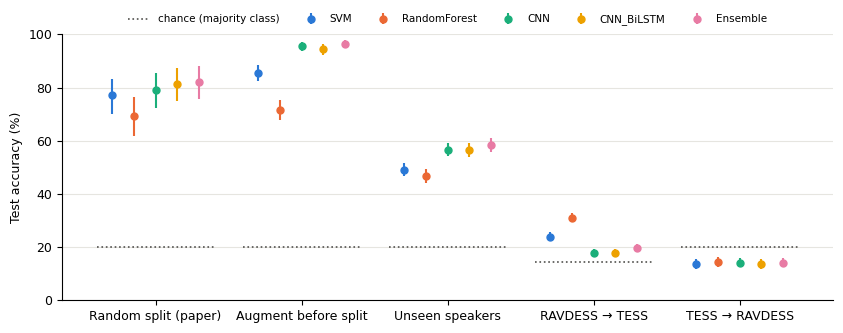

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
shown = MODELS[1:]
for i, (exp, name) in enumerate(PROTOCOLS.items()):
    for j, model in enumerate(shown):
        r = metrics[(metrics["experiment"] == exp) & (metrics["model"] == model)].iloc[0]
        x = i + (j - 2) * 0.15
        ax.errorbar(x, 100 * r["accuracy"], yerr=[[100 * (r["accuracy"] - r["ci_low"])],
                    [100 * (r["ci_high"] - r["accuracy"])]], fmt="o", ms=5, lw=1.5, capsize=0,
                    color=COLORS[model], label=model if i == 0 else None)
    chance = metrics[(metrics["experiment"] == exp) & (metrics["model"] == "Majority")]["accuracy"].item()
    ax.hlines(100 * chance, i - 0.4, i + 0.4, color="#52514e", ls=":", lw=1.2,
              label="chance (majority class)" if i == 0 else None)
ax.set_xticks(range(len(PROTOCOLS)), PROTOCOLS.values())
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", color="#e6e5e0")
ax.legend(ncol=6, fontsize=7.5, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.tight_layout()
plt.savefig(OUT / "figures" / "fig1_accuracy_ci.png", dpi=200)
plt.show()

## 4. Error analysis — where the model does well and where it fails
We analyse the ensemble (the paper's final model).

### 4.1 Per emotion

In [8]:
ens = main[main["model"] == "Ensemble"]
for exp in ["paper", "speaker"]:
    d = ens[ens["experiment"] == exp]
    print(f"--- {PROTOCOLS[exp]} ---")
    print(classification_report(d["label"], d["pred"], labels=range(7), target_names=EMOTIONS, digits=3,
                                zero_division=0))


def recall_per_emotion(df):
    """Share of the clips of each emotion that are recognised correctly."""
    return df.groupby("emotion")["correct"].mean().reindex(EMOTIONS)


recalls = pd.DataFrame({PROTOCOLS[e]: recall_per_emotion(ens[ens["experiment"] == e])
                        for e in ["paper", "speaker", "ravdess_to_tess"]})
print((100 * recalls).round(1))

--- Random split (paper) ---
              precision    recall  f1-score   support

     neutral      0.844     0.931     0.885        29
       happy      0.824     0.737     0.778        19
         sad      0.682     0.789     0.732        19
       angry      0.941     0.842     0.889        19
     fearful      0.882     0.750     0.811        20
     disgust      0.773     0.895     0.829        19
   surprised      0.824     0.737     0.778        19

    accuracy                          0.819       144
   macro avg      0.824     0.812     0.814       144
weighted avg      0.826     0.819     0.819       144

--- Unseen speakers ---
              precision    recall  f1-score   support

     neutral      0.647     0.642     0.645       288
       happy      0.515     0.531     0.523       192
         sad      0.400     0.344     0.370       192
       angry      0.709     0.734     0.721       192
     fearful      0.580     0.526     0.552       192
     disgust      0.537  

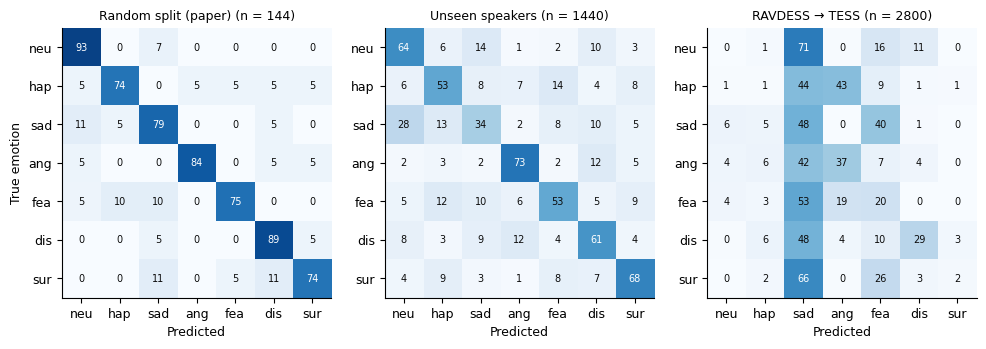

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3))
short = ["neu", "hap", "sad", "ang", "fea", "dis", "sur"]
for ax, exp in zip(axes, ["paper", "speaker", "ravdess_to_tess"]):
    d = ens[ens["experiment"] == exp]
    cm = confusion_matrix(d["label"], d["pred"], labels=range(7), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(7):
        for j in range(7):
            ax.text(j, i, f"{100 * cm[i, j]:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 0.55 else "#0b0b0b")
    ax.set_xticks(range(7), short)
    ax.set_yticks(range(7), short)
    ax.set_xlabel("Predicted")
    ax.set_title(f"{PROTOCOLS[exp]} (n = {len(d)})", fontsize=9)
axes[0].set_ylabel("True emotion")
plt.tight_layout()
plt.savefig(OUT / "figures" / "fig2_confusion.png", dpi=200)
plt.show()

### 4.2 Most common mistakes for unseen speakers

In [10]:
d = ens[ens["experiment"] == "speaker"]
cm = confusion_matrix(d["label"], d["pred"], labels=range(7))
mistakes = [(EMOTIONS[i], EMOTIONS[j], cm[i, j], cm[i, j] / cm[i].sum())
            for i in range(7) for j in range(7) if i != j]
mistakes = pd.DataFrame(mistakes, columns=["true", "predicted", "clips", "share of true class"])
print(mistakes.sort_values("clips", ascending=False).head(6).round(3).to_string(index=False))

   true predicted  clips  share of true class
    sad   neutral     53                0.276
neutral       sad     39                0.135
neutral   disgust     28                0.097
  happy   fearful     26                0.135
    sad     happy     25                0.130
  angry   disgust     24                0.125


### 4.3 Normal vs strong emotional intensity
RAVDESS actors speak every emotion at a normal and a strong intensity (4th number in the file name).
Plain neutral has no strong version, so neutral clips are left out of this comparison.

In [11]:
def two_proportion_test(correct_a, correct_b):
    """Two-sided z-test: are two accuracies different?"""
    a, b = np.mean(correct_a), np.mean(correct_b)
    na, nb = len(correct_a), len(correct_b)
    pooled = (a * na + b * nb) / (na + nb)
    z = (a - b) / np.sqrt(pooled * (1 - pooled) * (1 / na + 1 / nb))
    return a, b, 2 * (1 - norm.cdf(abs(z)))


d = ens[(ens["experiment"] == "speaker") & (ens["emotion"] != "neutral")].copy()
d["intensity"] = d["path"].str.extract(r"03-01-\d\d-(\d\d)")[0].map({"01": "normal", "02": "strong"})
normal, strong, p = two_proportion_test(d[d["intensity"] == "normal"]["correct"],
                                        d[d["intensity"] == "strong"]["correct"])
print(f"Unseen speakers, ensemble: normal intensity {100 * normal:.1f}%, strong {100 * strong:.1f}% "
      f"(p = {p:.2g}, {(d['intensity'] == 'normal').sum()} vs {(d['intensity'] == 'strong').sum()} clips)")

Unseen speakers, ensemble: normal intensity 47.9%, strong 66.1% (p = 4.1e-10, 576 vs 576 clips)


### 4.4 Per speaker (unseen speakers)

In [12]:
actors = (ens[ens["experiment"] == "speaker"].groupby(["speaker", "gender"])["correct"].mean()
          .reset_index().sort_values("correct"))
print(f"Per-actor accuracy: lowest {100 * actors['correct'].min():.1f}% "
      f"({', '.join(actors[actors['correct'] == actors['correct'].min()]['speaker'])}), highest "
      f"{100 * actors['correct'].max():.1f}% ({actors.iloc[-1]['speaker']}), median "
      f"{100 * actors['correct'].median():.1f}%")

Per-actor accuracy: lowest 40.0% (R09, R17, R23), highest 81.7% (R08), median 57.5%


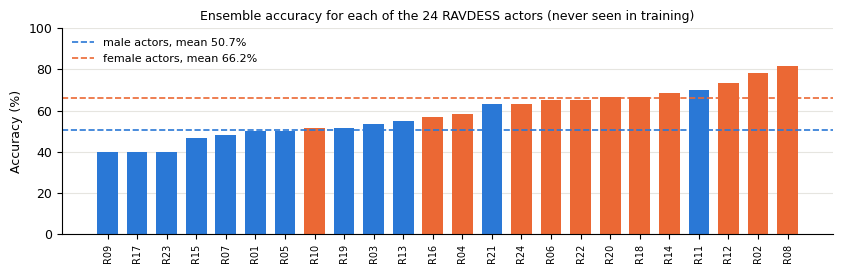

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 2.8))
colors = ["#2a78d6" if g == "male" else "#eb6834" for g in actors["gender"]]
ax.bar(range(len(actors)), 100 * actors["correct"], color=colors, width=0.7)
for g, c in [("male", "#2a78d6"), ("female", "#eb6834")]:
    mean = 100 * actors[actors["gender"] == g]["correct"].mean()
    ax.axhline(mean, color=c, ls="--", lw=1.2, label=f"{g} actors, mean {mean:.1f}%")
ax.set_xticks(range(len(actors)), actors["speaker"], fontsize=7, rotation=90)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", color="#e6e5e0")
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Ensemble accuracy for each of the 24 RAVDESS actors (never seen in training)", fontsize=9)
plt.tight_layout()
plt.savefig(OUT / "figures" / "fig3_actors.png", dpi=200)
plt.show()

### 4.5 Unseen dataset (RAVDESS → TESS)

In [14]:
d = ens[ens["experiment"] == "ravdess_to_tess"]
share = d["pred"].map(dict(enumerate(EMOTIONS))).value_counts(normalize=True).reindex(EMOTIONS, fill_value=0)
print("Share of TESS clips predicted as each emotion (true share is 14.3% each):")
print((100 * share).round(1).to_string())
print("Accuracy per TESS speaker:", (100 * d.groupby("speaker")["correct"].mean()).round(1).to_dict())
offset = json.load(open(RESULTS / "tess_offset_check.json"))
for k, v in offset.items():
    print(f"{k}: padded frames {100 * v['padded_frames']:.1f}%, accuracy {100 * v['acc']:.1f}%, "
          f"predicted sad {100 * v['pred_sad_share']:.1f}%")

Share of TESS clips predicted as each emotion (true share is 14.3% each):
pred
neutral       2.3
happy         3.4
sad          53.1
angry        14.9
fearful      18.3
disgust       7.2
surprised     0.9
Accuracy per TESS speaker: {'OAF': 15.5, 'YAF': 23.9}
offset_0.6: padded frames 41.5%, accuracy 19.7%, predicted sad 53.1%
offset_0.0: padded frames 18.0%, accuracy 30.5%, predicted sad 11.1%


### 4.6 Augment before split: why accuracy looks so high

In [15]:
d = ens[ens["experiment"] == "leaky"]
overlap = json.load(open(RESULTS / "leaky_overlap.json"))["test_samples_with_a_copy_in_train"]
print(f"Test samples with an augmented copy of the same recording in training: {100 * overlap:.1f}%")
print((100 * d.groupby("augmentation")["correct"].mean()).round(1).to_string())

Test samples with an augmented copy of the same recording in training: 99.1%
augmentation
noise          95.8
noise_pitch    95.6
original       97.8
pitch          97.1


## 5. Bias check: male vs female speakers
Unseen-speaker protocol: every clip is tested by a model that never heard that actor. RAVDESS is balanced
(12 male and 12 female actors, 720 clips each), so a gap cannot come from unequal data.

In [16]:
rows = []
for model in MODELS[1:]:
    d = speaker[speaker["model"] == model]
    male, female = d[d["gender"] == "male"], d[d["gender"] == "female"]
    acc_m, acc_f, p = two_proportion_test(male["correct"], female["correct"])
    rows.append({"model": model, "male acc": 100 * acc_m, "female acc": 100 * acc_f,
                 "male macro-F1": 100 * scores(male)["macro_F1"], "female macro-F1": 100 * scores(female)["macro_F1"],
                 "gap (F - M)": 100 * (acc_f - acc_m), "p_value": p})
bias = pd.DataFrame(rows)
bias.to_csv(OUT / "gender_bias.csv", index=False)
print(bias.round(4).to_string(index=False))

       model  male acc  female acc  male macro-F1  female macro-F1  gap (F - M)  p_value
         SVM   45.2778     52.9167        44.6927          52.7284       7.6389   0.0037
RandomForest   40.9722     52.6389        37.1614          49.4130      11.6667   0.0000
         CNN   49.4444     63.8889        48.7762          63.0178      14.4444   0.0000
  CNN_BiLSTM   47.2222     65.8333        47.3947          64.8762      18.6111   0.0000
    Ensemble   50.6944     66.2500        50.3155          65.1309      15.5556   0.0000


In [17]:
male_acc = actors[actors["gender"] == "male"]["correct"]
female_acc = actors[actors["gender"] == "female"]["correct"]
test = mannwhitneyu(female_acc, male_acc, alternative="two-sided")
print(f"Actor level (ensemble): female mean {100 * female_acc.mean():.1f}%, male mean {100 * male_acc.mean():.1f}%, "
      f"Mann-Whitney U = {test.statistic:.0f}, p = {test.pvalue:.4f}")

d = speaker[speaker["model"] == "Ensemble"]
by_emotion = d.groupby(["emotion", "gender"])["correct"].mean().unstack().reindex(EMOTIONS)
by_emotion["gap (F - M)"] = by_emotion["female"] - by_emotion["male"]
print((100 * by_emotion).round(1))

Actor level (ensemble): female mean 66.2%, male mean 50.7%, Mann-Whitney U = 129, p = 0.0011
gender     female  male  gap (F - M)
emotion                             
neutral      74.3  54.2         20.1
happy        52.1  54.2         -2.1
sad          38.5  30.2          8.3
angry        79.2  67.7         11.5
fearful      61.5  43.8         17.7
disgust      70.8  51.0         19.8
surprised    83.3  52.1         31.2


In [18]:
d = main[(main["experiment"] == "paper") & (main["model"] == "Ensemble")]
acc_m, acc_f, p = two_proportion_test(d[d["gender"] == "male"]["correct"], d[d["gender"] == "female"]["correct"])
print(f"Random split (paper protocol), ensemble: male {100 * acc_m:.1f}%, female {100 * acc_f:.1f}%, p = {p:.2f} "
      f"({(d['gender'] == 'male').sum()} vs {(d['gender'] == 'female').sum()} clips)")

Random split (paper protocol), ensemble: male 80.0%, female 84.4%, p = 0.50 (80 vs 64 clips)


## 6. Key results in one place

In [19]:
def acc(exp, model):
    """Accuracy (%) and 95% interval of one model under one protocol, as text."""
    r = metrics[(metrics["experiment"] == exp) & (metrics["model"] == model)].iloc[0]
    return f"{100 * r['accuracy']:.1f}% [{100 * r['ci_low']:.1f}–{100 * r['ci_high']:.1f}]"


for exp, name in PROTOCOLS.items():
    print(f"{name:22s} ensemble {acc(exp, 'Ensemble'):22s} SVM {acc(exp, 'SVM')}")

Random split (paper)   ensemble 81.9% [75.7–88.2]      SVM 77.1% [70.1–83.3]
Augment before split   ensemble 96.5% [95.0–97.9]      SVM 85.6% [82.6–88.5]
Unseen speakers        ensemble 58.5% [55.9–61.0]      SVM 49.1% [46.6–51.7]
RAVDESS → TESS         ensemble 19.7% [18.2–21.1]      SVM 23.9% [22.4–25.6]
TESS → RAVDESS         ensemble 14.1% [12.4–15.8]      SVM 13.6% [11.9–15.4]
